In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('/content/class_ipl_22-26_dataset.csv')

# Q1

In [6]:
mean = df['team1_runs'].mean()
median = df['team1_runs'].median()
mode = df['team1_runs'].mode()[0]
std = df['team1_runs'].std()
max = df['team1_runs'].max()
min = df['team1_runs'].min()

print('Mean:', mean)
print('Median:', median)
print('Mode:', mode)
print('std:',std)
print('max:',max)
print('min:',min)

Mean: 185.0708446866485
Median: 187.0
Mode: 159
std: 36.51626473597981
max: 287
min: 25


In [8]:
team1_analysis = df.groupby('team1').agg(
    mean = ('team1_runs','mean'),
    median = ('team1_runs','median'),
    mode = ('team1_runs',lambda x: x.mode()[0]),
    std = ('team1_runs','std'),
    max = ('team1_runs','max'),
    min = ('team1_runs','min')
)
team1_analysis

,mean,median,mode,std,max,min
team1,,,,,,
Chennai Super Kings,181.658537,187.0,154,33.985004,235,97
Delhi Capitals,180.642857,178.5,159,40.746019,264,75
Gujarat Titans,186.382353,194.0,168,33.551421,233,89
Kolkata Knight Riders,181.558824,179.5,179,46.161896,272,25
Lucknow Super Giants,185.731707,180.0,159,29.364114,257,125
Mumbai Indians,180.218750,178.0,155,29.529356,243,125
Punjab Kings,183.894737,189.0,214,38.789654,254,101
Rajasthan Royals,183.615385,188.0,193,30.302523,243,118
Royal Challengers Bangalore,175.833333,181.0,174,33.706781,212,68


<Axes: xlabel='team1_runs', ylabel='Count'>

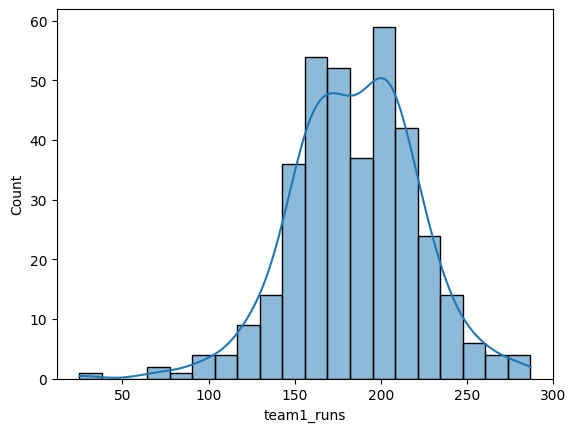

In [10]:
sns.histplot(df['team1_runs'],kde=True)

<Axes: xlabel='team1_runs', ylabel='Density'>

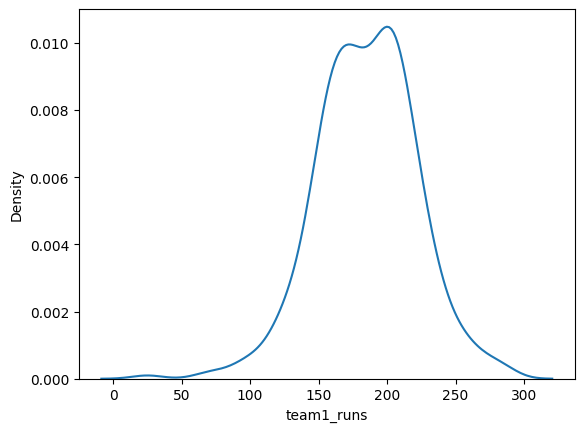

In [11]:
sns.kdeplot(df['team1_runs'])

<Axes: ylabel='team1_runs'>

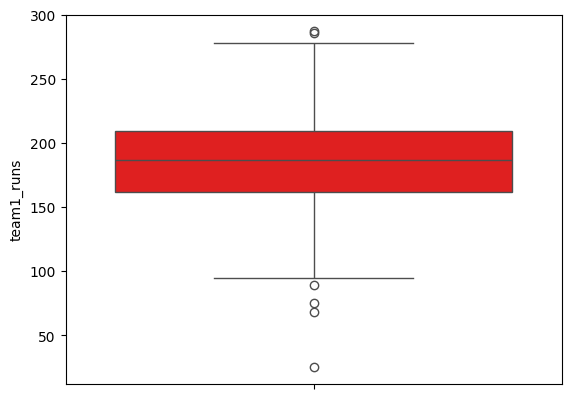

In [12]:
sns.boxplot(df['team1_runs'],color='red')

# Q2

In [14]:
highest_venue=df['venue'].value_counts()
highest_venue

,count
venue,
"Wankhede Stadium, Mumbai",49
"Narendra Modi Stadium, Ahmedabad",36
"MA Chidambaram Stadium, Chepauk, Chennai",31
"Eden Gardens, Kolkata",30
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",29
"Rajiv Gandhi International Stadium, Uppal, Hyderabad",26
"Arun Jaitley Stadium, Delhi",26
"M Chinnaswamy Stadium, Bengaluru",24
"Sawai Mansingh Stadium, Jaipur",21


<Axes: xlabel='count', ylabel='venue'>

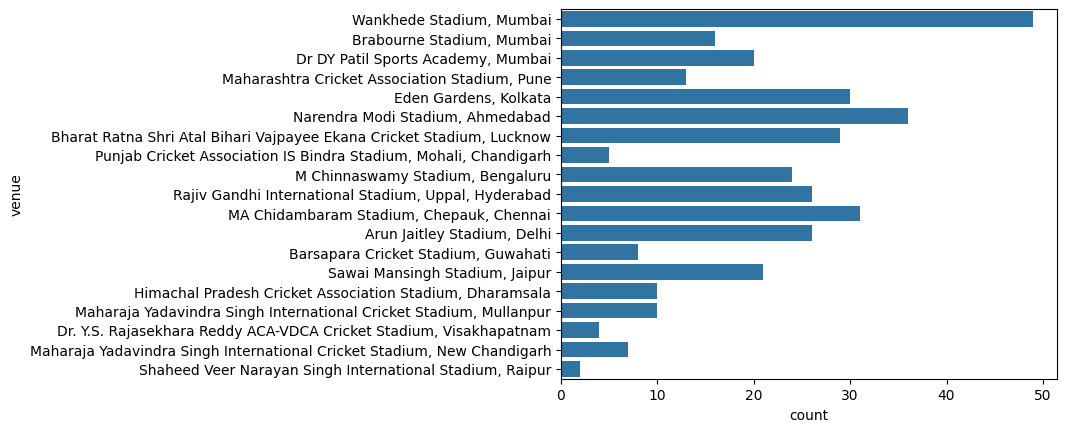

In [26]:
sns.countplot(df['venue'])

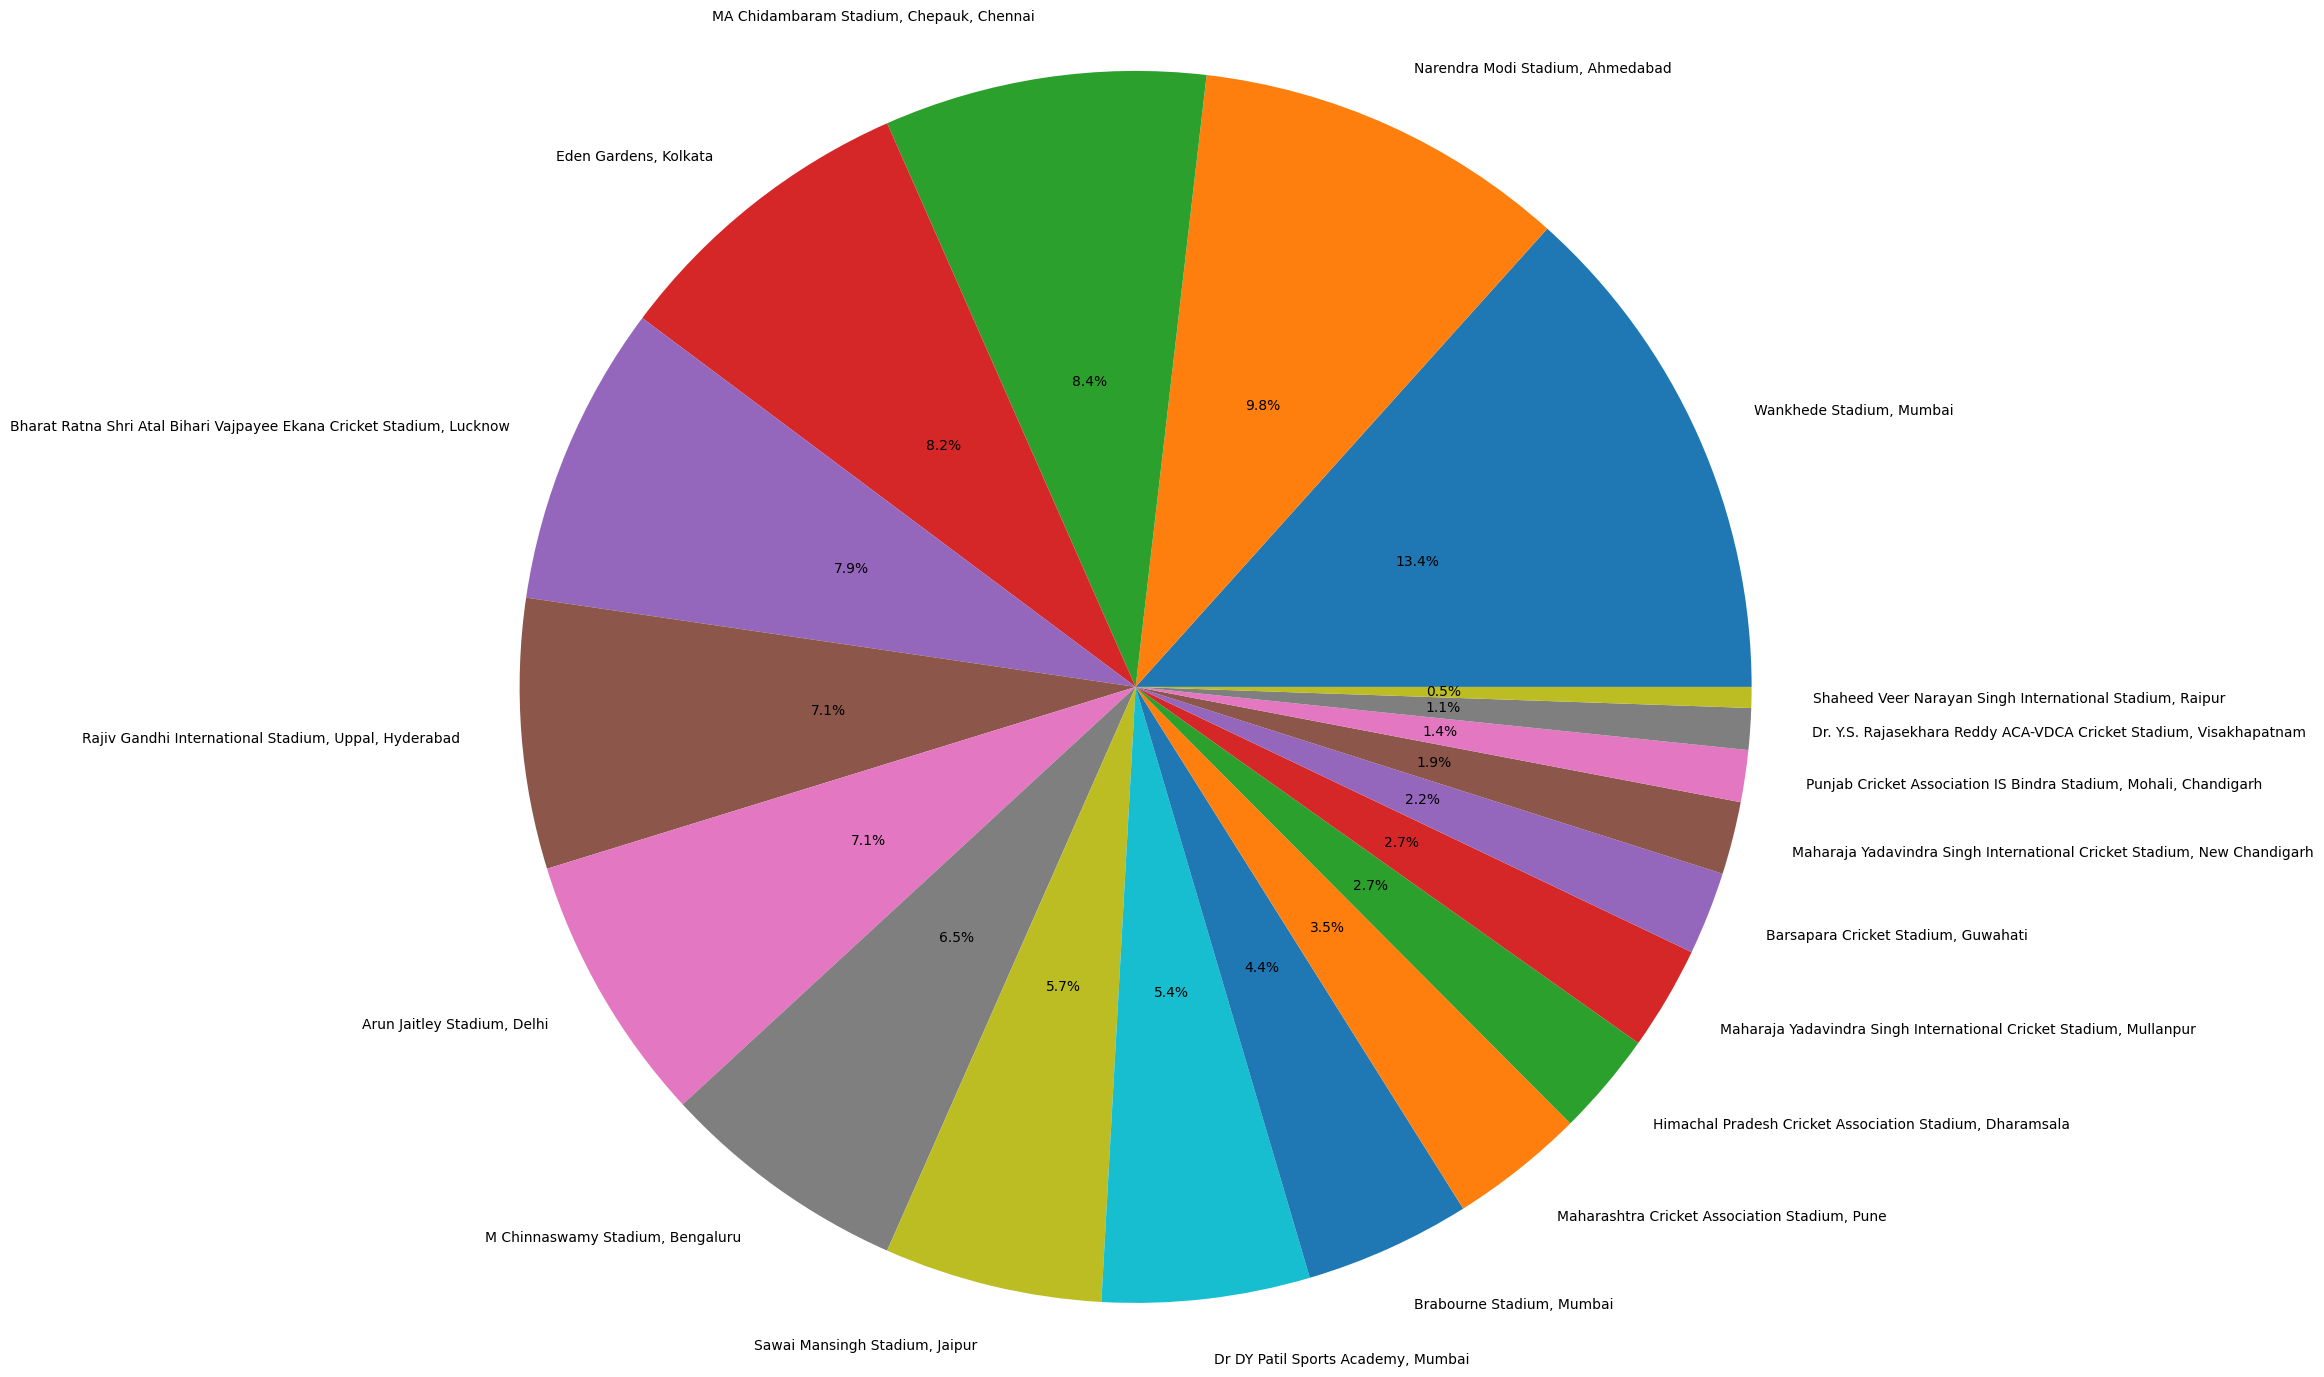

In [22]:
plt.figure(figsize=(10,10))
plt.pie(x=highest_venue.values,labels=highest_venue.index,autopct='%1.1f%%',pctdistance=0.5,radius=2)
plt.show()

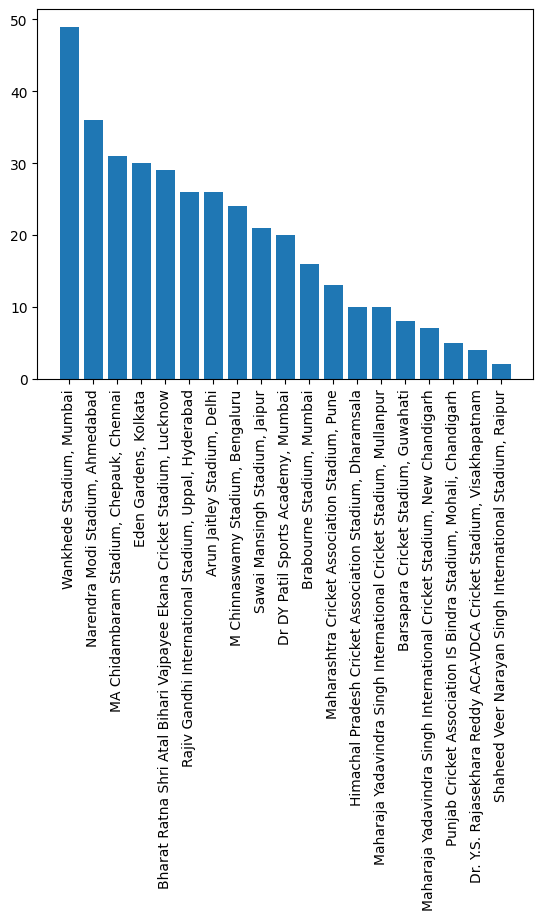

In [30]:
plt.bar(x=highest_venue.index,height=highest_venue.values)
plt.xticks(rotation=90)
plt.show()

# Q3

In [32]:
toss = df['toss_decision'].value_counts()
toss

,count
toss_decision,
field,285
bat,82


<Axes: xlabel='count', ylabel='toss_decision'>

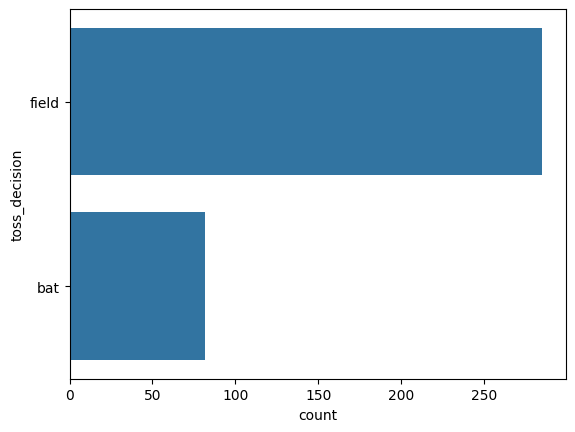

In [33]:
sns.countplot(df['toss_decision'])

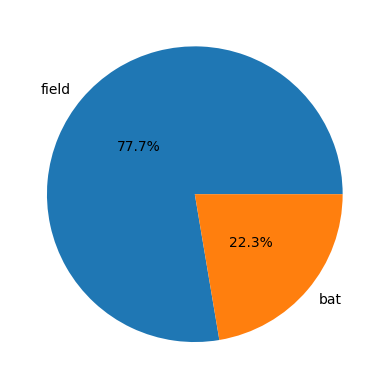

In [34]:
plt.pie(x=toss.values,labels=toss.index,autopct='%1.1f%%',pctdistance=0.5)
plt.show()

In [42]:
mode = df['toss_decision'].mode()[0]
batting_percentage =toss.bat.sum()/(toss.bat.sum()+ toss.field.sum())*100
fielding_percentage =toss.field.sum()/(toss.bat.sum()+ toss.field.sum())*100
print('Mode:',mode)
print('Batting Percentage:',batting_percentage)
print('Fielding Percentage:',fielding_percentage)

Mode: field
Batting Percentage: 22.3433242506812
Fielding Percentage: 77.65667574931881


# Q4

In [68]:
df['toss_win_match_win']=df['toss_winner']==df['winner']


In [77]:
win=df['toss_win_match_win'].value_counts()
win.va

array([360,   7])

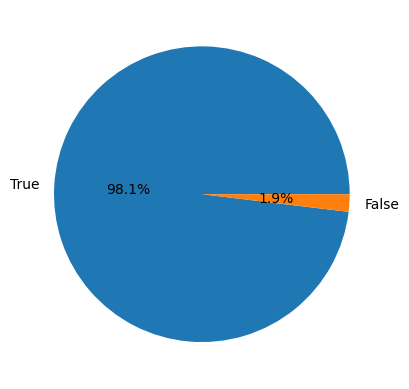

In [69]:
plt.pie(x=win.values,labels=win.index,autopct='%1.1f%%',pctdistance=0.5)
plt.show()

# Q5


In [80]:
df['team1_runs'].corr(df['team2_runs'])


np.float64(0.7016680094722738)

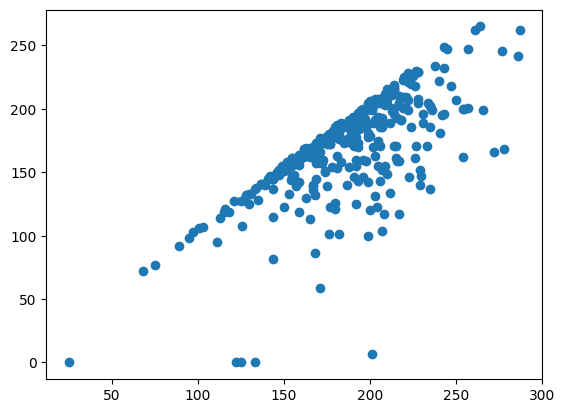

In [81]:
plt.scatter(x=df['team1_runs'],y=df['team2_runs'])
plt.show()

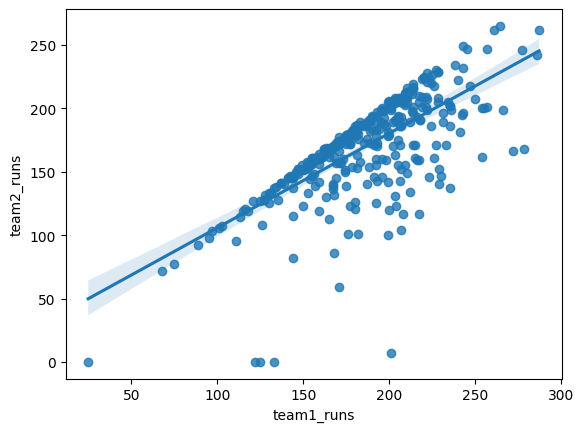

In [83]:
sns.regplot(x=df['team1_runs'],y=df['team2_runs'])
plt.show()

# Q6

In [87]:
df["team1_runs"].iloc[10:20]= None
df['city'].iloc[30:35,]= None


/tmp/ipykernel_3086/1682938776.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["team1_runs"].iloc[10:20]= None
/tmp/ipykernel_3086/1682938776.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are se

,team1_runs
10,NaN
11,NaN
12,NaN
13,NaN
14,NaN
15,NaN
16,NaN
17,NaN
18,NaN
19,NaN


<Axes: >

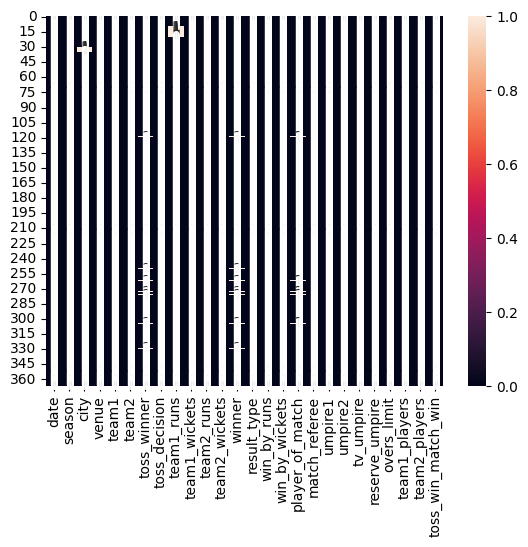

In [102]:
sns.heatmap(df.isna(),annot=True)

In [94]:
df.isnull().sum()

,0
date,0
season,0
city,5
venue,0
team1,0
team2,0
toss_winner,7
toss_decision,0
team1_runs,10
team1_wickets,0


# Q7

In [104]:
df.isna().sum()

,0
date,0
season,0
city,5
venue,0
team1,0
team2,0
toss_winner,7
toss_decision,0
team1_runs,10
team1_wickets,0


In [134]:
sum=df.isna().sum().count()
precentage = (sum/df.size)*100
print("Percentage: ",precentage)


Percentage:  0.2724795640326975


In [141]:
#highest Missing value Column
df.isna().sum().idxmax()

'team1_runs'

<Axes: >

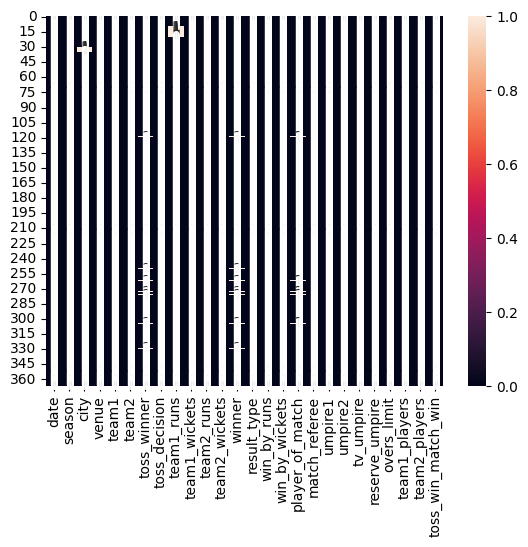

In [144]:
sns.heatmap(df.isna(),annot=True)

# Q8

In [177]:
avg = df[['team1_runs','venue'] ]
avg = avg.groupby('venue').mean()
avg

,team1_runs
venue,
"Arun Jaitley Stadium, Delhi",193.923077
"Barsapara Cricket Stadium, Guwahati",168.875000
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",174.931034
"Brabourne Stadium, Mumbai",173.230769
"Dr DY Patil Sports Academy, Mumbai",173.058824
"Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",208.750000
"Eden Gardens, Kolkata",190.333333
"Himachal Pradesh Cricket Association Stadium, Dharamsala",205.200000
"M Chinnaswamy Stadium, Bengaluru",190.375000


# Q9

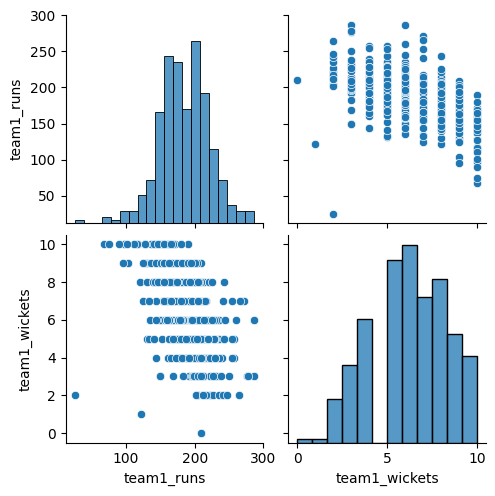

In [6]:
# Q9
sns.pairplot(
    df[['team1_runs','team1_wickets','toss_decision','winner']]
)
plt.show()

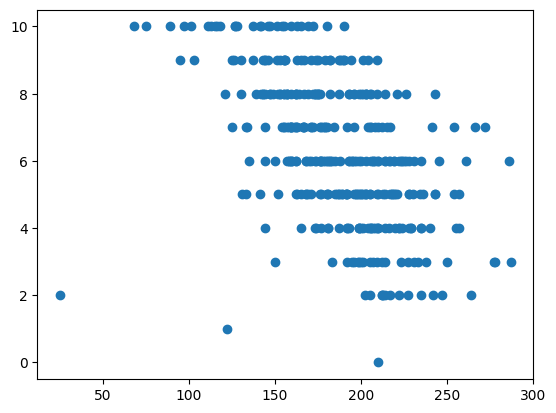

In [184]:
plt.scatter(x=df['team1_runs'],y=df['team1_wickets'])
plt.show()

# Q10

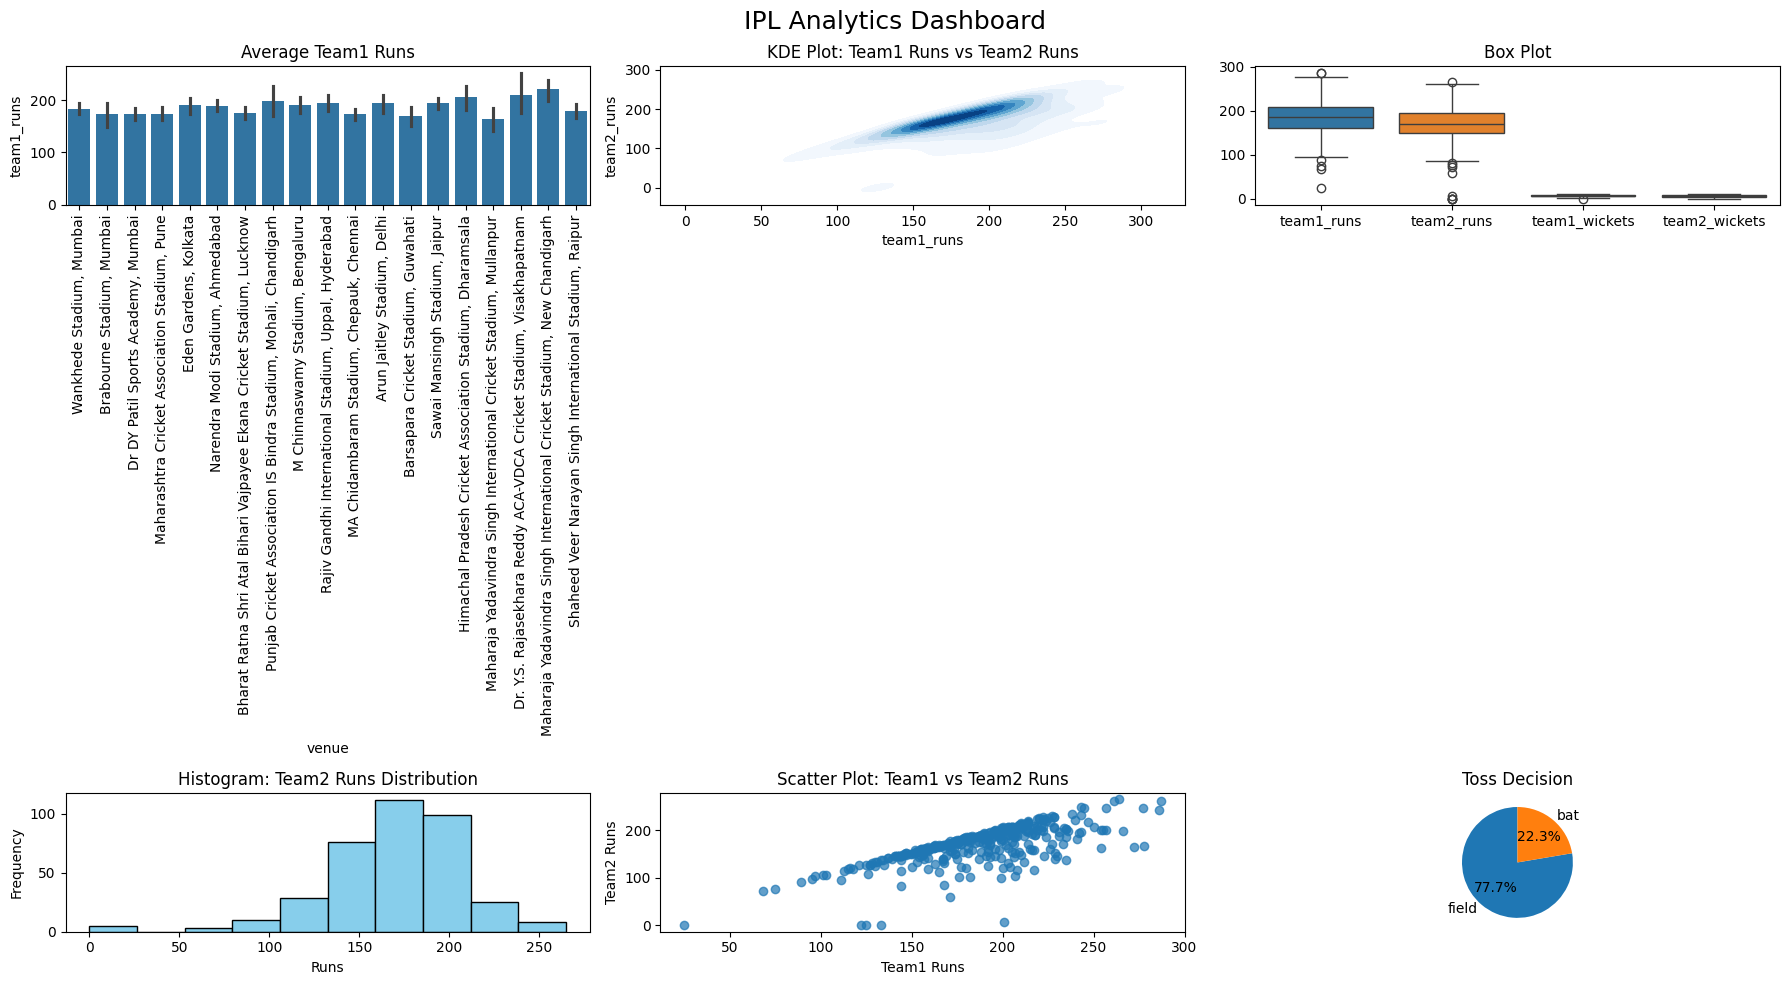

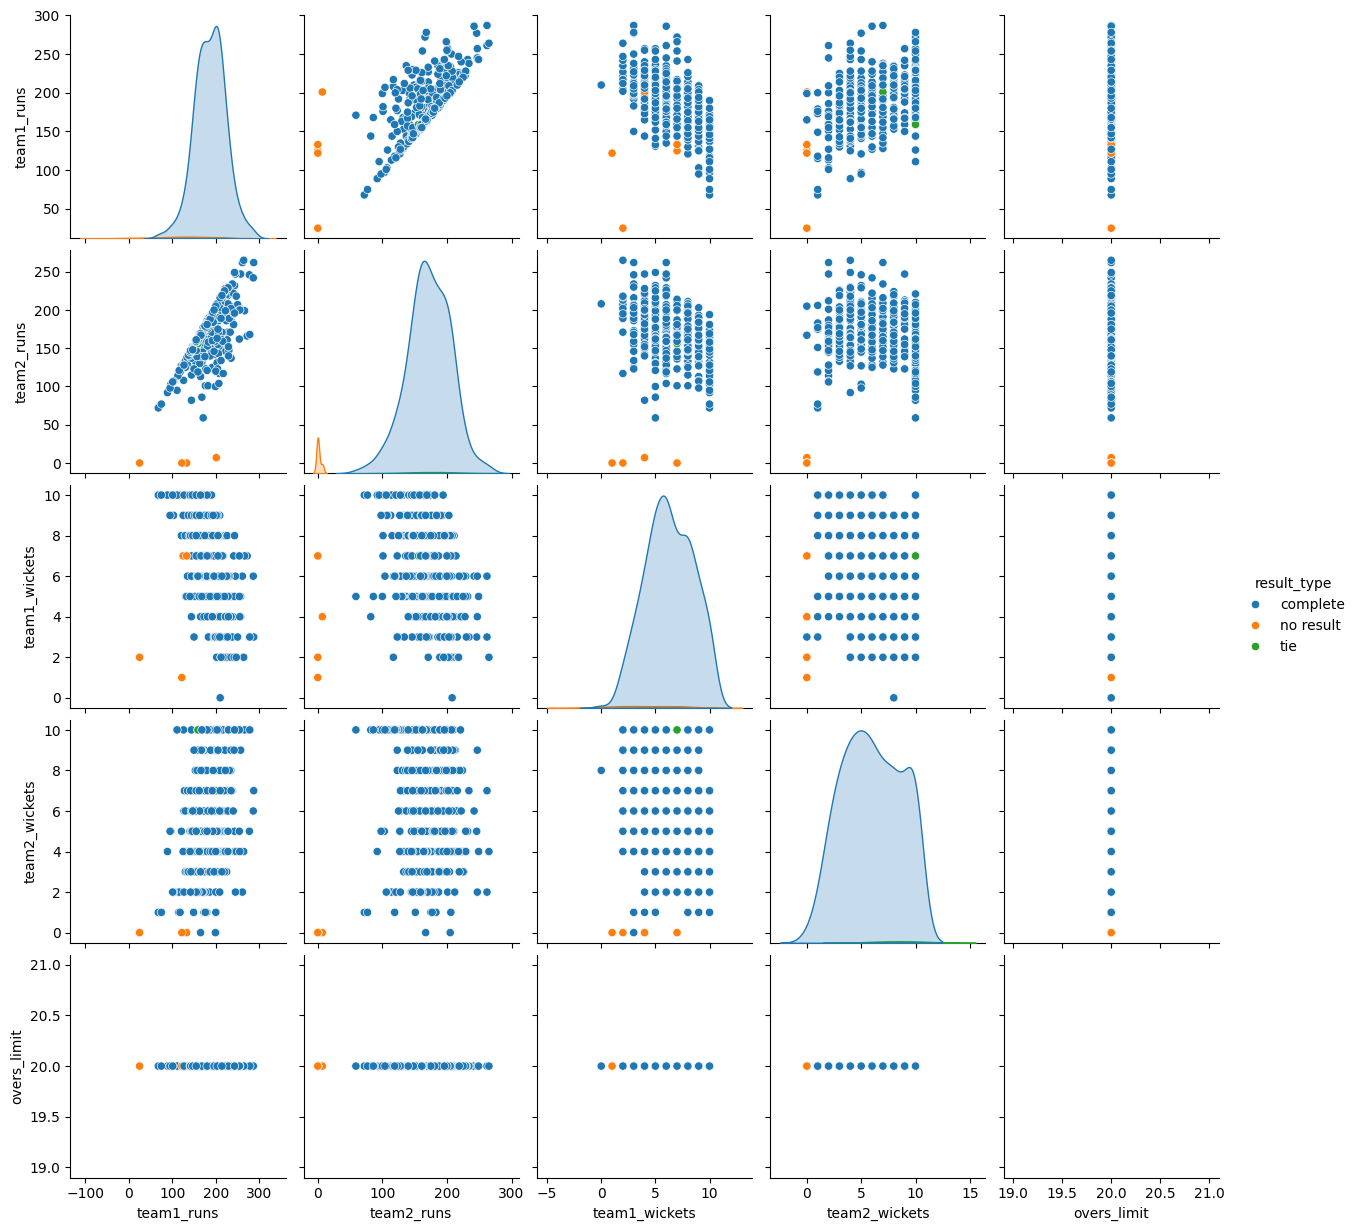

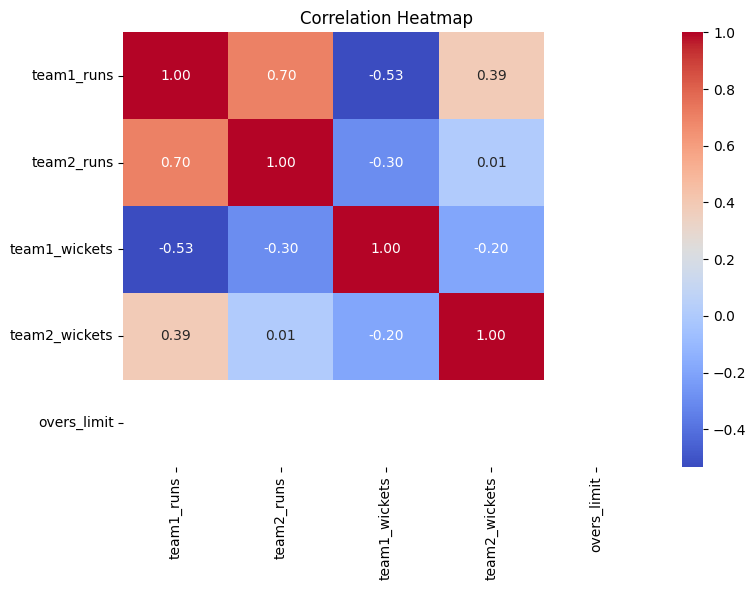

In [198]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.barplot( x='venue', y='team1_runs', data=df, ax=axes[0, 0] )
axes[0, 0].set_title('Average Team1 Runs')
axes[0, 0].tick_params(axis='x', rotation=90)

sns.kdeplot( x='team1_runs', y='team2_runs', data=df, fill=True, cmap='Blues', ax=axes[0, 1] )
axes[0, 1].set_title('KDE Plot: Team1 Runs vs Team2 Runs')

sns.boxplot( data=df[['team1_runs', 'team2_runs', 'team1_wickets', 'team2_wickets']], ax=axes[0, 2] )
axes[0, 2].set_title('Box Plot')

axes[1, 0].hist( df['team2_runs'], bins=10, color='skyblue', edgecolor='black' )
axes[1, 0].set_title('Histogram: Team2 Runs Distribution')
axes[1, 0].set_xlabel('Runs')
axes[1, 0].set_ylabel('Frequency')

axes[1, 1].scatter( df['team1_runs'], df['team2_runs'], alpha=0.7 )
axes[1, 1].set_title('Scatter Plot: Team1 vs Team2 Runs')
axes[1, 1].set_xlabel('Team1 Runs')
axes[1, 1].set_ylabel('Team2 Runs')

result = df['toss_decision'].value_counts()
axes[1, 2].pie( result.values, labels=result.index, autopct='%1.1f%%', startangle=90 )
axes[1, 2].set_title('Toss Decision')

plt.suptitle('IPL Analytics Dashboard', fontsize=18)
plt.tight_layout()
plt.show()

pairplot_cols = [ 'team1_runs', 'team2_runs', 'team1_wickets', 'team2_wickets', 'overs_limit', 'result_type' ]
sns.pairplot( df[pairplot_cols], hue='result_type', diag_kind='kde' )
plt.show()

numerical_cols = [ 'team1_runs', 'team2_runs', 'team1_wickets', 'team2_wickets', 'overs_limit' ]
corr_matrix = df[numerical_cols].corr()
plt.figure(figsize=(8, 6))

sns.heatmap( corr_matrix, annot=True, cmap='coolwarm', fmt='.2f' )
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()